## Import Libraries

In [118]:
!pip install -q scikit-image

In [119]:
import gc
import heapq
import math
import os

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
from pyproj import Transformer
import rasterio
from rasterio.windows import Window
from scipy.ndimage import gaussian_filter
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from skimage.graph import route_through_array

import numpy as np
import rasterio
from rasterio.windows import Window
from pyproj import Transformer
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import heapq
import numpy as np
import rasterio
from rasterio.windows import Window
from pyproj import Transformer
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import heapq
import numpy as np
import rasterio
from rasterio.windows import Window
from pyproj import Transformer
from scipy.ndimage import gaussian_filter, binary_dilation
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import heapq
import numpy as np
import rasterio
from rasterio.windows import Window
from pyproj import Transformer
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import heapq
import numpy as np
import rasterio
from rasterio.windows import Window
from pyproj import Transformer
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

## Import Data for Gale Crater -- Bradbury Landing

## datasets:

Topography: MSL_Gale_DEM_Mosaic_1m_v3.tif

Weather: https://atmos.nmsu.edu/PDS/data/PDS4/msl_rems_bundle/data_calibrated/SOL_00001_00089/SOL00001/RME_397535244ADR00010000000_______P9.TAB


Radiation: https://atmos.nmsu.edu/PDS/data/PDS4/msl_rems_bundle/data_uv_corrected/REMS_UVS_0001_0100.TAB

###  Weather

In [120]:
!wget https://atmos.nmsu.edu/PDS/data/PDS4/msl_rems_bundle/data_calibrated/SOL_00001_00089/SOL00001/RME_397535244ADR00010000000_______P9.TAB


--2026-11-15 03:42:12--  https://atmos.nmsu.edu/PDS/data/PDS4/msl_rems_bundle/data_calibrated/SOL_00001_00089/SOL00001/RME_397535244ADR00010000000_______P9.TAB
Resolving atmos.nmsu.edu (atmos.nmsu.edu)... 128.123.88.210
Connecting to atmos.nmsu.edu (atmos.nmsu.edu)|128.123.88.210|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 114152 (111K)
Saving to: ‘RME_397535244ADR00010000000_______P9.TAB.2’

RME_397535244ADR000 100%[===================>] 111.48K   444KB/s    in 0.3s    

2026-11-15 03:42:13 (444 KB/s) - ‘RME_397535244ADR00010000000_______P9.TAB.2’ saved [114152/114152]



### topography

In [121]:
file_path = "/content/MSL_Gale_DEM_Mosaic_1m_v3.tif"

### Look at the topography

File size: 3.60 GB
Dimensions: 32980 x 57440
Bands: 1, Data Type: float32
CRS: ESRI:103885
Bounds: BoundingBox(left=8127993.492786024, bottom=-302221.075189438, right=8160973.492786024, top=-244781.075189438)
Overview array shape: (3590, 2061)
Full-res crop shape: (1000, 1000)


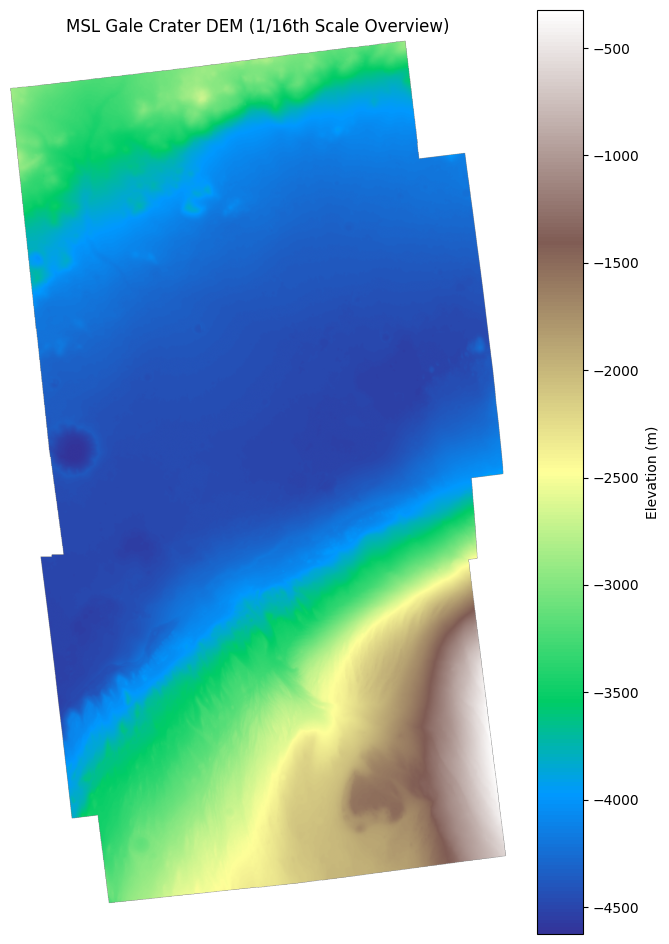

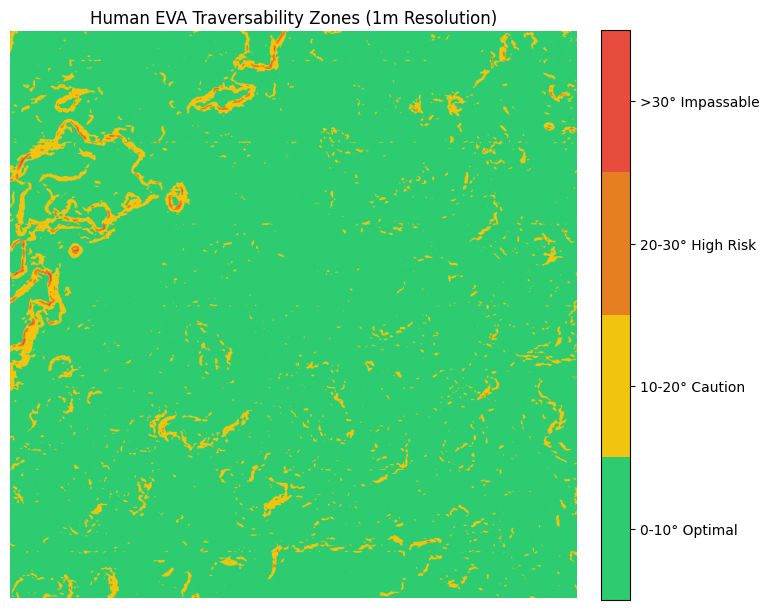

In [122]:
# verify and check size
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found at {file_path}")

size_gb = os.path.getsize(file_path) / (1024**3)
print(f"File size: {size_gb:.2f} GB")

# geotiff
with rasterio.open(file_path) as src:
    print(f"Dimensions: {src.width} x {src.height}")
    print(f"Bands: {src.count}, Data Type: {src.dtypes[0]}")
    print(f"CRS: {src.crs}")
    print(f"Bounds: {src.bounds}")

    # Store nodata value and pixel resolution before closing the file
    nodata_val = src.nodata
    res_x, res_y = src.res  # Should be (1.0, 1.0) meters

    # 1/16th downsampled overview of the whole DEM (~3590 x 2061 px)
    overview = src.read(
        1,
        out_shape=(src.height // 16, src.width // 16)
    )
    print(f"Overview array shape: {overview.shape}")

    # Read a full-resolution 1000x1000m crop from the center
    center_window = Window(
        col_off=src.width // 2 - 500,
        row_off=src.height // 2 - 500,
        width=1000,
        height=1000
    )
    crop = src.read(1, window=center_window)
    print(f"Full-res crop shape: {crop.shape}")

# NoData values safely (handles None and extreme float sentinels)
overview_clean = overview.astype(np.float32)
crop_clean = crop.astype(np.float32)

if nodata_val is not None:
    overview_clean = np.where(np.isclose(overview_clean, nodata_val), np.nan, overview_clean)
    crop_clean = np.where(np.isclose(crop_clean, nodata_val), np.nan, crop_clean)

# Also mask extreme float32 fill values commonly used in planetary DEMs
overview_clean = np.where(overview_clean < -1e10, np.nan, overview_clean)
crop_clean = np.where(crop_clean < -1e10, np.nan, crop_clean)

# Visualize the overview
plt.figure(figsize=(8, 12))
plt.imshow(overview_clean, cmap="terrain")
plt.colorbar(label="Elevation (m)")
plt.title("MSL Gale Crater DEM (1/16th Scale Overview)")
plt.axis("off")
plt.show()

# Compute slope gradient in degrees using exact pixel spacing
dy, dx = np.gradient(crop_clean, res_y, res_x)
slope_deg = np.degrees(np.arctan(np.hypot(dx, dy)))

# Classify into human traversability tiers: 0=Optimal, 1=Caution, 2=High Risk, 3=Impassable
zones = np.digitize(slope_deg, bins=[10, 20, 30])
zones = np.where(np.isnan(slope_deg), -1, zones)  # Keep NoData separate

cmap = ListedColormap(["#2ecc71", "#f1c40f", "#e67e22", "#e74c3c"])
plt.figure(figsize=(8, 8))
plt.imshow(np.ma.masked_where(zones == -1, zones), cmap=cmap, vmin=0, vmax=3)
cbar = plt.colorbar(ticks=[0.375, 1.125, 1.875, 2.625], fraction=0.046, pad=0.04)
cbar.ax.set_yticklabels(["0-10° Optimal", "10-20° Caution", "20-30° High Risk", ">30° Impassable"])
plt.title("Human EVA Traversability Zones (1m Resolution)")
plt.axis("off")
plt.show()


## Plot areas of interest

Bradbury Landing               -> Row: 27260, Col: 18821
Yellowknife Bay                -> Row: 27171, Col: 19284
The Kimberley                  -> Row: 29868, Col: 15638
Pahrump Hills (Mt Sharp Base)  -> Row: 31616, Col: 15520
Murray Buttes                  -> Row: 33928, Col: 15223
Vera Rubin Ridge               -> Row: 35647, Col: 15579
Glen Torridon                  -> Row: 36299, Col: 15697


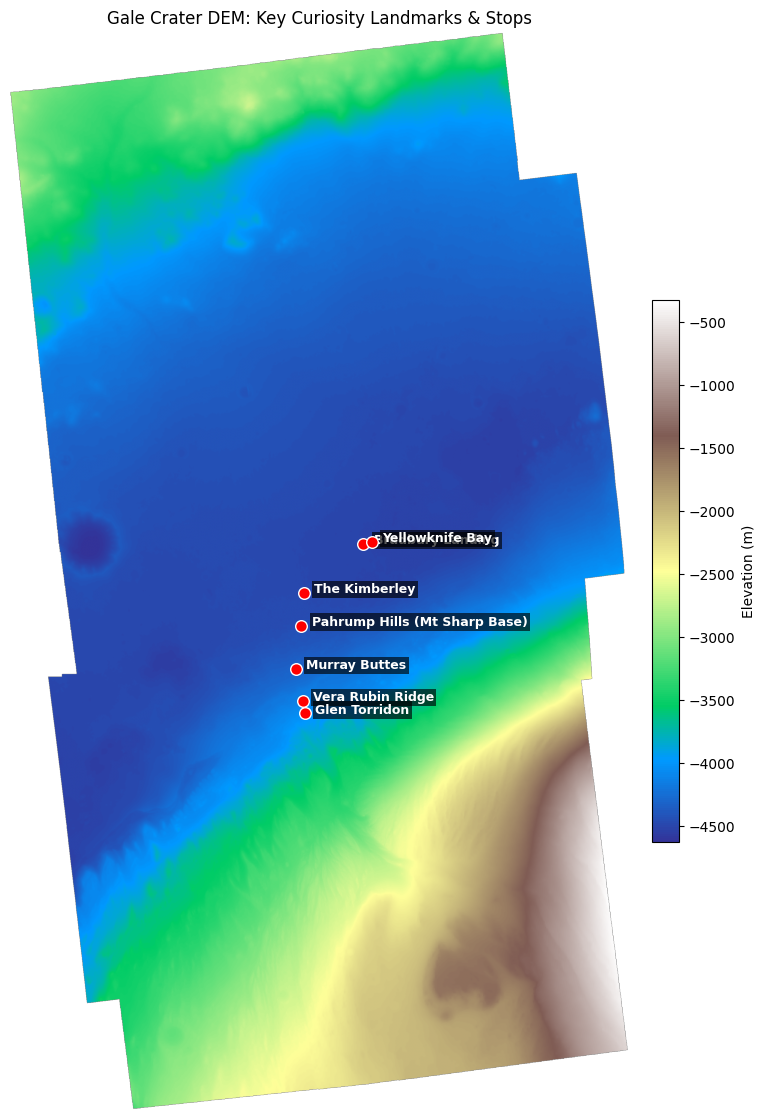

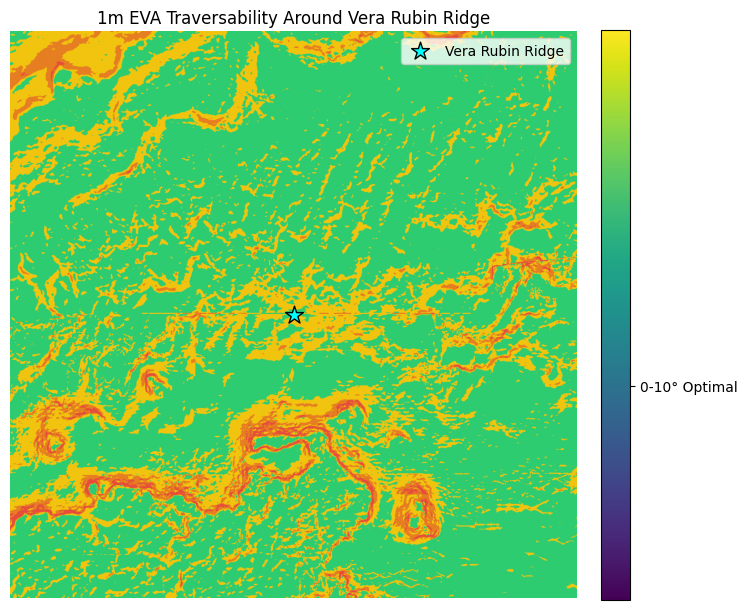

In [123]:
file_path = "/content/MSL_Gale_DEM_Mosaic_1m_v3.tif"

# 1. Key Gale Crater Landmarks (Planetocentric Lat, East Lon)
landmarks = {
    "Bradbury Landing": (-4.5895, 137.4417),
    "Yellowknife Bay": (-4.5880, 137.4495),
    "The Kimberley": (-4.6335, 137.3880),
    "Pahrump Hills (Mt Sharp Base)": (-4.6630, 137.3860),
    "Murray Buttes": (-4.7020, 137.3810),
    "Vera Rubin Ridge": (-4.7310, 137.3870),
    "Glen Torridon": (-4.7420, 137.3890),
}

with rasterio.open(file_path) as src:
    nodata_val = src.nodata
    res_x, res_y = src.res

    # Set up transformer from Mars Geographic (Equirectangular sphere R=3396190m) to dataset CRS
    mars_geo_crs = "+proj=longlat +a=3396190 +b=3396190 +no_defs"
    transformer = Transformer.from_crs(mars_geo_crs, src.crs, always_xy=True)

    # Convert each landmark to full-res (row, col) pixel indices
    pixel_coords = {}
    for name, (lat, lon) in landmarks.items():
        x_proj, y_proj = transformer.transform(lon, lat)
        row, col = src.index(x_proj, y_proj)
        pixel_coords[name] = (row, col)
        print(f"{name:30s} -> Row: {row:5d}, Col: {col:5d}")

    # 2. Read 1/16th overview map
    scale = 16
    overview = src.read(1, out_shape=(src.height // scale, src.width // scale)).astype(np.float32)
    if nodata_val is not None:
        overview = np.where(np.isclose(overview, nodata_val), np.nan, overview)
    overview = np.where(overview < -1e10, np.nan, overview)

    # 3. Plot Overview with Landmark Pins
    plt.figure(figsize=(10, 14))
    plt.imshow(overview, cmap="terrain")
    plt.colorbar(label="Elevation (m)", fraction=0.035, pad=0.03)

    for name, (row, col) in pixel_coords.items():
        r_scaled, c_scaled = row / scale, col / scale
        plt.scatter(c_scaled, r_scaled, color="red", edgecolor="white", s=70, zorder=5)
        plt.text(
            c_scaled + 35, r_scaled, name,
            color="white", fontsize=9, fontweight="bold",
            bbox=dict(facecolor="black", alpha=0.65, edgecolor="none", pad=1.5)
        )

    plt.title("Gale Crater DEM: Key Curiosity Landmarks & Stops")
    plt.axis("off")
    plt.show()

    # 4. Generate 1m EVA Traversability Map for a Chosen Stop
    target_stop = "Vera Rubin Ridge"  # <-- Change to any landmark name above!
    t_row, t_col = pixel_coords[target_stop]
    half_size = 500  # 1000m x 1000m window

    stop_window = Window(
        col_off=max(0, t_col - half_size),
        row_off=max(0, t_row - half_size),
        width=half_size * 2,
        height=half_size * 2
    )
    crop = src.read(1, window=stop_window).astype(np.float32)

# Clean NoData & compute slope
if nodata_val is not None:
    crop = np.where(np.isclose(crop, nodata_val), np.nan, crop)
crop = np.where(crop < -1e10, np.nan, crop)

dy, dx = np.gradient(crop, res_y, res_x)
slope_deg = np.degrees(np.arctan(np.hypot(dx, dy)))

zones = np.digitize(slope_deg, bins=[10, 20, 30])
zones = np.where(np.isnan(slope_deg), -1, zones)

cmap = ListedColormap(["#2ecc71", "#f1c40f", "#e67e22", "#e74c3c"])
plt.figure(figsize=(8, 8))
plt.imshow(np.ma.masked_where(zones == -1, zones), cmap=cmap, vmin=0, vmax=3)
plt.scatter(half_size, half_size, color="cyan", edgecolor="black", marker="*", s=180, label=target_stop)
plt.legend(loc="upper right")

cbar = plt.colorbar(ticks=[0.375, 1.125, 1.875, 2.625], fraction=0.046, pad=0.04)
cbar.ax.set_yticklabels(["0-10° Optimal", "10-20° Caution", "20-30° High Risk", ">30° Impassable"])
plt.title(f"1m EVA Traversability Around {target_stop}")
plt.axis("off")
plt.show()


## Map between spots

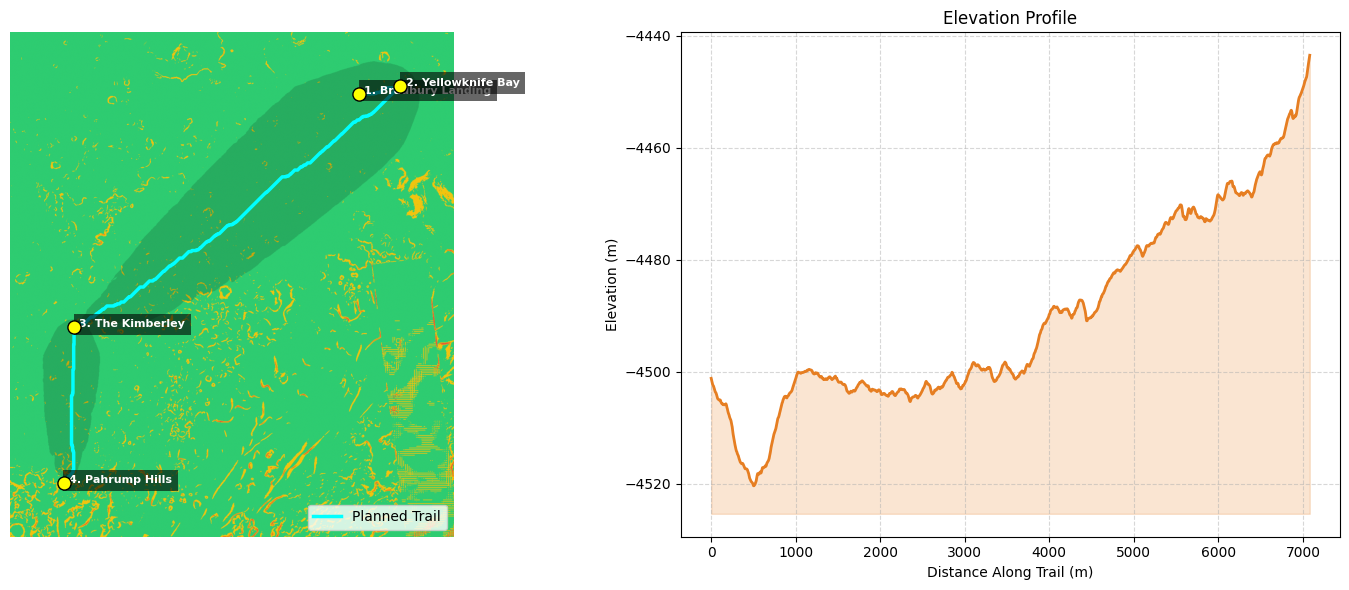


Trail successfully calculated! Total Distance: 7081.1 m | Duration: 2h 56m
Saved Assets for Unity: gale_terrain_1025.raw, unity_manifest.json, unity_trail_waypoints.csv


In [124]:
# --- 1. CONFIGURATION & LANDMARKS ---
file_path = "/content/MSL_Gale_DEM_Mosaic_1m_v3.tif"
if not os.path.exists(file_path):
    raise FileNotFoundError(f"File not found at {file_path}")

landmarks = {
    "Bradbury Landing": (-4.5895, 137.4417),
    "Yellowknife Bay": (-4.5880, 137.4495),
    "The Kimberley": (-4.6335, 137.3880),
    "Pahrump Hills": (-4.6630, 137.3860),
    "Murray Buttes": (-4.7020, 137.3810),
    "Vera Rubin Ridge": (-4.7310, 137.3870),
    "Glen Torridon": (-4.7420, 137.3890),
}

itinerary = ["Bradbury Landing", "Yellowknife Bay", "The Kimberley", "Pahrump Hills"]
DEM_LAT_BOUNDS = (-5.098652, -4.129605)
DEM_LON_BOUNDS = (137.124167, 137.680559)

# --- 2. RESOLVE ITINERARY & CROPPING BOUNDS ---
def resolve_itinerary(stops_input):
    resolved = []
    for idx, pt in enumerate(stops_input):
        if isinstance(pt, str):
            lat, lon = landmarks[pt]
            label = pt
        else:
            lat, lon = float(pt[0]), float(pt[1])
            label = f"Pin {idx+1} ({lat:.4f}°, {lon:.4f}°)"
        resolved.append((label, lat, lon))
    return resolved

resolved_stops = resolve_itinerary(itinerary)
stop_labels = [s[0] for s in resolved_stops]

with rasterio.open(file_path) as src:
    nodata_val = src.nodata
    res_x, res_y = src.res
    transformer = Transformer.from_crs("+proj=longlat +a=3396190 +b=3396190 +no_defs", src.crs, always_xy=True)

    def latlon_to_rowcol(lat, lon):
        x, y = transformer.transform(lon, lat)
        return src.index(x, y)

    all_pixels = [latlon_to_rowcol(lat, lon) for _, lat, lon in resolved_stops]
    all_r, all_c = [p[0] for p in all_pixels], [p[1] for p in all_pixels]

    pad = 600
    row_min, row_max = max(0, min(all_r) - pad), min(src.height, max(all_r) + pad)
    col_min, col_max = max(0, min(all_c) - pad), min(src.width, max(all_c) + pad)

    win_h, win_w = row_max - row_min, col_max - col_min
    STEP = max(4, int(np.ceil(max(win_h, win_w) / 1500)))

    H, W = win_h // STEP, win_w // STEP
    window = Window(col_min, row_min, win_w, win_h)
    dem = src.read(1, window=window, out_shape=(H, W)).astype(np.float32)

eff_res_x = float(res_x * STEP)
eff_res_y = float(res_y * STEP)

# --- 3. CLEAN & SMOOTH DATA ---
if nodata_val is not None:
    dem = np.where(np.isclose(dem, nodata_val), np.nan, dem)
dem = np.where(dem < -1e10, np.nan, dem)
dem_smooth = gaussian_filter(np.where(np.isnan(dem), np.nanmean(dem), dem), sigma=0.8)
dem_smooth[np.isnan(dem)] = np.nan

dy, dx = np.gradient(dem_smooth, eff_res_y, eff_res_x)
ground_tilt_deg = np.degrees(np.arctan(np.hypot(dx, dy))).astype(np.float32)

# --- 4. MULTI-LEG A* SEARCH ---
MAX_FORWARD_DEG = 18.0
MAX_SIDESLOPE_DEG = 25.0
stop_rcs = [(int(np.clip((r - row_min) // STEP, 0, H - 1)), int(np.clip((c - col_min) // STEP, 0, W - 1))) for r, c in all_pixels]
neighbors = [
    (-1, 0, eff_res_y), (1, 0, eff_res_y), (0, -1, eff_res_x), (0, 1, eff_res_x),
    (-1, -1, float(np.hypot(eff_res_x, eff_res_y))), (-1, 1, float(np.hypot(eff_res_x, eff_res_y))),
    (1, -1, float(np.hypot(eff_res_x, eff_res_y))), (1, 1, float(np.hypot(eff_res_x, eff_res_y)))
]
passable = (~np.isnan(dem_smooth)) & (ground_tilt_deg <= MAX_SIDESLOPE_DEG)

def run_astar_leg(sr, sc, er, ec):
    g_score = np.full((H, W), np.inf, dtype=np.float32)
    g_score[sr, sc] = 0.0
    parent_r, parent_c = np.full((H, W), -1, dtype=np.int32), np.full((H, W), -1, dtype=np.int32)
    closed = np.zeros((H, W), dtype=bool)
    open_heap = [(float(np.hypot((sc - ec) * eff_res_x, (sr - er) * eff_res_y)), 0.0, sr, sc)]

    while open_heap:
        _, g_curr, r, c = heapq.heappop(open_heap)
        if closed[r, c]:
            continue
        closed[r, c] = True
        if r == er and c == ec:
            rows, cols = [], []
            while r != -1 and c != -1:
                rows.append(r); cols.append(c)
                if r == sr and c == sc: break
                r, c = parent_r[r, c], parent_c[r, c]
            return np.array(rows[::-1]), np.array(cols[::-1]), closed

        z_curr = float(dem_smooth[r, c])
        for dr, dc, horiz_dist in neighbors:
            nr, nc = r + dr, c + dc
            if not (0 <= nr < H and 0 <= nc < W) or closed[nr, nc] or not passable[nr, nc]:
                continue
            forward_deg = np.degrees(np.arctan((float(dem_smooth[nr, nc]) - z_curr) / horiz_dist))
            if abs(forward_deg) > MAX_FORWARD_DEG:
                continue
            step_cost = horiz_dist * (1.0 + (forward_deg / 8.0) ** 2.5 if forward_deg >= 0 else 1.0 + (-forward_deg / 12.0) ** 2.0)
            if g_curr + step_cost < g_score[nr, nc]:
                g_score[nr, nc] = g_curr + step_cost
                parent_r[nr, nc], parent_c[nr, nc] = r, c
                h_val = float(np.hypot((nc - ec) * eff_res_x, (nr - er) * eff_res_y))
                heapq.heappush(open_heap, (g_curr + step_cost + h_val, g_curr + step_cost, nr, nc))
    return None, None, closed

all_path_rows, all_path_cols, all_closed = [], [], np.zeros((H, W), dtype=bool)
stop_cumulative_dists = [0.0]

for i in range(len(stop_rcs) - 1):
    leg_r, leg_c, leg_closed = run_astar_leg(*stop_rcs[i], *stop_rcs[i+1])
    all_closed |= leg_closed
    if leg_r is None:
        raise RuntimeError(f"A* failed on leg: {stop_labels[i]} -> {stop_labels[i+1]}")
    leg_dists = np.hypot(np.diff(leg_c) * eff_res_x, np.diff(leg_r) * eff_res_y)
    stop_cumulative_dists.append(stop_cumulative_dists[-1] + float(np.sum(leg_dists)))
    if i > 0:
        leg_r, leg_c = leg_r[1:], leg_c[1:]
    all_path_rows.append(leg_r); all_path_cols.append(leg_c)

path_rows = np.concatenate(all_path_rows)
path_cols = np.concatenate(all_path_cols)

# --- 5. TRAIL METRICS & TIMING ---
step_dists = np.hypot(np.diff(path_cols) * eff_res_x, np.diff(path_rows) * eff_res_y)
cum_dist = np.insert(np.cumsum(step_dists), 0, 0.0)
elev_profile = dem_smooth[path_rows, path_cols]
elev_diffs = np.diff(elev_profile)
directional_grades_deg = np.degrees(np.arctan(elev_diffs / step_dists))

speed_kmh = 3.0 * np.exp(-3.5 * np.abs((elev_diffs / step_dists) + 0.05))
step_speed_ms = np.maximum(speed_kmh * (1000.0 / 3600.0), 0.1)
total_seconds = float(np.sum(step_dists / step_speed_ms))
hours, mins = divmod(int(round(total_seconds / 60.0)), 60)
time_str = f"{hours}h {mins}m" if hours > 0 else f"{mins}m"

# --- 6. PLOT DIAGNOSTIC MAP ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.1, 1]})
zones = np.digitize(ground_tilt_deg, bins=[10, 20, 30])
zones = np.where(np.isnan(ground_tilt_deg), -1, zones)
cmap = ListedColormap(["#2ecc71", "#f1c40f", "#e67e22", "#e74c3c"])
ax1.imshow(np.ma.masked_where(zones == -1, zones), cmap=cmap, vmin=0, vmax=3)
ax1.imshow(np.ma.masked_where(~all_closed, all_closed), cmap=ListedColormap(["#000000"]), alpha=0.15)
ax1.plot(path_cols, path_rows, color="#00ffff", linewidth=2.5, label="Planned Trail")

for idx, (sr, sc) in enumerate(stop_rcs):
    ax1.scatter(sc, sr, color="yellow", edgecolor="black", s=90, zorder=6)
    ax1.text(sc + 15, sr, f"{idx+1}. {stop_labels[idx]}", color="white", fontsize=8, fontweight="bold", bbox=dict(facecolor="black", alpha=0.6, edgecolor="none"))

ax1.set_xlim(0, W - 1); ax1.set_ylim(H - 1, 0); ax1.axis("off")
ax1.legend(loc="lower right")

ax2.plot(cum_dist, elev_profile, color="#e67e22", linewidth=2)
ax2.fill_between(cum_dist, elev_profile, np.nanmin(elev_profile) - 5, color="#e67e22", alpha=0.2)
ax2.set_title("Elevation Profile")
ax2.set_xlabel("Distance Along Trail (m)"); ax2.set_ylabel("Elevation (m)")
ax2.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()

# --- 7. EXPORT TO UNITY CORNERSTONE ASSETS ---
with rasterio.open(file_path) as src:
    origin_x, _ = rasterio.transform.xy(src.transform, row_min, col_min, offset="ul")
    _, origin_z = rasterio.transform.xy(src.transform, row_max, col_min, offset="ll")
    max_x, max_z = rasterio.transform.xy(src.transform, row_min, col_max, offset="ur")

terrain_width_m = float(max_x - origin_x)
terrain_length_m = float(max_z - origin_z)
dem_clean = np.nan_to_num(dem_smooth, nan=float(np.nanmin(dem_smooth)))
min_elev_m, max_elev_m = float(np.min(dem_clean)), float(np.max(dem_clean))
terrain_height_m = max(max_elev_m - min_elev_m, 1.0)

# Resample heightmap for Unity (1025x1025 16-bit raw)
dem_norm = np.clip((zoom(dem_clean, (1025 / H, 1025 / W), order=1) - min_elev_m) / terrain_height_m, 0.0, 1.0)
((dem_norm * 65535).astype("<u2")).tofile("/content/gale_terrain_1025.raw")

# Export coordinate manifest
manifest = {
    "heightmap_file": "gale_terrain_1025.raw",
    "heightmap_resolution": 1025,
    "unity_terrain_size": {"x_width_m": round(terrain_width_m, 2), "y_height_m": round(terrain_height_m, 2), "z_length_m": round(terrain_length_m, 2)},
    "mars_origin_anchor": {"origin_easting_m": round(origin_x, 2), "origin_northing_m": round(origin_z, 2), "base_elevation_m": round(min_elev_m, 2)},
    "landmarks_unity_xyz": {}
}

for name, (lat, lon) in landmarks.items():
    px_x, px_z = transformer.transform(lon, lat)
    if origin_x <= px_x <= max_x and origin_z <= px_z <= max_z:
        r_idx = int(np.clip((row_max - latlon_to_rowcol(lat, lon)[0]) / (row_max - row_min) * (H - 1), 0, H - 1))
        c_idx = int(np.clip((latlon_to_rowcol(lat, lon)[1] - col_min) / (col_max - col_min) * (W - 1), 0, W - 1))
        manifest["landmarks_unity_xyz"][name] = {
            "x": round(px_x - origin_x, 2),
            "y": round(float(dem_clean[H - 1 - r_idx, c_idx]) - min_elev_m, 2),
            "z": round(px_z - origin_z, 2)
        }

with open("/content/unity_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

# Export waypoints in relative Unity coordinates
with rasterio.open(file_path) as src:
    wp_x, wp_z = rasterio.transform.xy(src.transform, row_min + path_rows * STEP, col_min + path_cols * STEP, offset="center")

pd.DataFrame({
    "waypoint_id": np.arange(len(path_rows)),
    "unity_x_m": np.round(np.array(wp_x) - origin_x, 2),
    "unity_y_m": np.round(elev_profile - min_elev_m, 2),
    "unity_z_m": np.round(np.array(wp_z) - origin_z, 2),
    "cum_distance_m": np.round(cum_dist, 2),
    "forward_grade_deg": np.round(np.insert(directional_grades_deg, 0, 0.0), 2),
    "side_slope_deg": np.round(ground_tilt_deg[path_rows, path_cols], 2),
    "cum_eva_time_sec": np.round(np.insert(np.cumsum(step_dists / step_speed_ms), 0, 0.0), 1),
}).to_csv("/content/unity_trail_waypoints.csv", index=False)

print(f"\nTrail successfully calculated! Total Distance: {cum_dist[-1]:.1f} m | Duration: {time_str}")
print("Saved Assets for Unity: gale_terrain_1025.raw, unity_manifest.json, unity_trail_waypoints.csv")

In [125]:
import itertools

# @title Martian Trail Recommender (Interactive Inputs)
start_location = "Bradbury Landing"  # @param ["Bradbury Landing", "Yellowknife Bay", "The Kimberley", "Pahrump Hills", "Murray Buttes", "Vera Rubin Ridge", "Glen Torridon"]
custom_start_lat_lon = ""  # @param {type:"string"}
target_difficulty = "MODERATE"  # @param ["ANY", "EASY", "MODERATE", "HARD"]
max_eva_minutes = 60  # @param {type:"slider", min:15, max:240, step:15}
trip_type = "Loop (Return to Start)"  # @param ["Loop (Return to Start)", "One-Way Point-to-Point"]

# 1. Parse optional custom (lat, lon) override if typed into the form
if custom_start_lat_lon.strip():
    parts = [float(x.strip()) for x in custom_start_lat_lon.split(",")]
    active_start = (parts[0], parts[1])
else:
    active_start = start_location

# 2. Helper to score any candidate itinerary using your existing DEM & A* logic
def evaluate_candidate_route(candidate_stops):
    resolved = resolve_itinerary(candidate_stops)
    labels = [item[0] for item in resolved]
    pixels = [latlon_to_rowcol(lat, lon) for _, lat, lon in resolved]

    # Map pixels into your currently loaded DEM window; skip if outside current crop
    grid_pts = []
    for r, c in pixels:
        gr = (r - row_min) // STEP
        gc = (c - col_min) // STEP
        if not (0 <= gr < H and 0 <= gc < W):
            return None
        grid_pts.append((int(gr), int(gc)))

    seg_r, seg_c = [], []
    for i in range(len(grid_pts) - 1):
        lr, lc, _ = run_astar_leg(*grid_pts[i], *grid_pts[i + 1])
        if lr is None:
            return None
        if i > 0:
            lr, lc = lr[1:], lc[1:]
        seg_r.append(lr)
        seg_c.append(lc)

    pr, pc = np.concatenate(seg_r), np.concatenate(seg_c)
    dists = np.hypot(np.diff(pc) * eff_res_x, np.diff(pr) * eff_res_y)
    total_m = float(np.sum(dists))

    elevs = dem_smooth[pr, pc]
    diffs = np.diff(elevs)
    grades = np.degrees(np.arctan(diffs / dists))

    gain = float(np.sum(diffs[diffs > 0]))
    max_climb = float(np.max(grades))
    max_side = float(np.max(ground_tilt_deg[pr, pc]))

    # Tobler Mars EVA time
    speeds_kmh = 3.0 * np.exp(-3.5 * np.abs((diffs / dists) + 0.05))
    speeds_ms = np.maximum(speeds_kmh * (1000.0 / 3600.0), 0.1)
    mins = float(np.sum(dists / speeds_ms) / 60.0)

    # Difficulty classification
    score = (total_m / 1000.0) * 1.5 + (gain / 50.0) * 2.0 + (max_climb / 10.0) * 1.5 + (max_side / 15.0) * 1.0
    if score < 3.0 and max_climb < 10.0:
        diff_cat = "EASY"
    elif score < 6.5 and max_climb < 15.0:
        diff_cat = "MODERATE"
    else:
        diff_cat = "HARD"

    return {
        "stops": candidate_stops,
        "route_str": " -> ".join(labels),
        "minutes": mins,
        "distance_km": total_m / 1000.0,
        "gain_m": gain,
        "difficulty": diff_cat,
        "score": score,
    }

# 3. Generate & filter candidate routes from available landmarks
other_landmarks = [name for name in landmarks if name != active_start]
candidate_itineraries = []

# Test 1-stop and 2-stop detours from the chosen start
for count in (1,2):
    for combo in itertools.permutations(other_landmarks, count):
        route = [active_start] + list(combo)
        if trip_type == "Loop (Return to Start)":
            route.append(active_start)
        candidate_itineraries.append(route)

matches = []
with rasterio.open(file_path) as src:
    for cand in candidate_itineraries:
        res = evaluate_candidate_route(cand)
        if res is None:
            continue
        if res["minutes"] <= max_eva_minutes:
            if target_difficulty == "ANY" or res["difficulty"] == target_difficulty:
                matches.append(res)

# Sort closest to the user's target time budget first
matches.sort(key=lambda x: abs(max_eva_minutes - x["minutes"]))

print(f"Found {len(matches)} matching trails (Target: {target_difficulty}, <= {max_eva_minutes} min):\n")
for idx, m in enumerate(matches[:5], 1):
    print(f"{idx}. [{m['difficulty']}] {m['route_str']}")
    print(f"   Est. Time: {int(round(m['minutes']))} min | Dist: {m['distance_km']:.2f} km | Gain: +{m['gain_m']:.1f} m\n")

# Automatically set `itinerary` to the top recommendation so you can re-plot it immediately
if matches:
    itinerary = matches[0]["stops"]
    print(f"Top match saved to `itinerary`: {itinerary}")
else:
    print("No routes fit that exact time/difficulty window—try increasing `max_eva_minutes` or setting `target_difficulty = 'ANY'`.")


Found 1 matching trails (Target: MODERATE, <= 60 min):

1. [MODERATE] Bradbury Landing -> Yellowknife Bay -> Bradbury Landing
   Est. Time: 25 min | Dist: 1.00 km | Gain: +19.9 m

Top match saved to `itinerary`: ['Bradbury Landing', 'Yellowknife Bay', 'Bradbury Landing']


## Add in radiation

In [126]:
# Download the metadata label (.LBL)
!wget https://atmos.nmsu.edu/PDS/data/PDS4/msl_rems_bundle/data_uv_corrected/REMS_UVS_0001_0100.LBL

# Download the data table (.TAB) - Note: ~1.2 GB file
!wget https://atmos.nmsu.edu/PDS/data/PDS4/msl_rems_bundle/data_uv_corrected/REMS_UVS_0001_0100.TAB


--2026-11-15 03:45:21--  https://atmos.nmsu.edu/PDS/data/PDS4/msl_rems_bundle/data_uv_corrected/REMS_UVS_0001_0100.LBL
Resolving atmos.nmsu.edu (atmos.nmsu.edu)... 128.123.88.210
Connecting to atmos.nmsu.edu (atmos.nmsu.edu)|128.123.88.210|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 21070 (21K) [text/plain]
Saving to: ‘REMS_UVS_0001_0100.LBL.1’

REMS_UVS_0001_0100. 100%[===================>]  20.58K  --.-KB/s    in 0s      

2026-11-15 03:45:21 (161 MB/s) - ‘REMS_UVS_0001_0100.LBL.1’ saved [21070/21070]

--2026-11-15 03:45:21--  https://atmos.nmsu.edu/PDS/data/PDS4/msl_rems_bundle/data_uv_corrected/REMS_UVS_0001_0100.TAB
Resolving atmos.nmsu.edu (atmos.nmsu.edu)... 128.123.88.210
Connecting to atmos.nmsu.edu (atmos.nmsu.edu)|128.123.88.210|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1199823100 (1.1G)
Saving to: ‘REMS_UVS_0001_0100.TAB.1’

REMS_UVS_0001_0100.   3%[                    ]  37.06M  2.00MB/s    eta 9m 27s ^C


## Add in weather

In [127]:
!rm -f index.html
!wget https://atmos.nmsu.edu/PDS/data/PDS4/msl_rems_bundle/data_calibrated/SOL_00001_00089/SOL00001/RME_397535244RNV00010000000_______PA.xml
!wget https://nmsu.edu

--2026-11-15 03:45:41--  https://atmos.nmsu.edu/PDS/data/PDS4/msl_rems_bundle/data_calibrated/SOL_00001_00089/SOL00001/RME_397535244RNV00010000000_______PA.xml
Resolving atmos.nmsu.edu (atmos.nmsu.edu)... 128.123.88.210
Connecting to atmos.nmsu.edu (atmos.nmsu.edu)|128.123.88.210|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 45020 (44K) [text/xml]
Saving to: ‘RME_397535244RNV00010000000_______PA.xml.1’

RME_397535244RNV000 100%[===================>]  43.96K  --.-KB/s    in 0s      

2026-11-15 03:45:41 (180 MB/s) - ‘RME_397535244RNV00010000000_______PA.xml.1’ saved [45020/45020]

--2026-11-15 03:45:41--  https://nmsu.edu/
Resolving nmsu.edu (nmsu.edu)... 216.21.13.176
Connecting to nmsu.edu (nmsu.edu)|216.21.13.176|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [text/html]
Saving to: ‘index.html’

index.html              [ <=>                ]  90.64K  --.-KB/s    in 0.1s    

2026-11-15 03:45:42 (743 KB/s) - ‘index.htm

### final warning system for UV and weather

In [131]:
# 1. Load real NASA REMS datasets
df_uv = pd.read_fwf(
    "/content/REMS_UVS_0001_0100.TAB",
    colspecs=[(5, 29), (309, 333)],
    names=["LMST_HOUR", "UV_ABC"],
    na_values=[-999, -999.0],
    nrows=200_000
).dropna()

df_adr = pd.read_csv(
    "/content/RME_397535244ADR00010000000_______P9.TAB",
    sep=None, engine="python", header=None, on_bad_lines="skip",
    na_values=[-999, -999.0, -9.990e+02, "XXXX", "XXXXXXX"]
)

# Extract real Gale Crater temperature (K -> °C) and pressure (Pa) ranges
temps_c, press_pa = [], []
for col in df_adr.columns:
    vals = pd.to_numeric(df_adr[col], errors="coerce").dropna()
    if len(vals) > 20:
        if 175.0 <= vals.median() <= 295.0:
            temps_c.extend((vals - 273.15).tolist())
        elif 650.0 <= vals.median() <= 1050.0:
            press_pa.extend(vals.tolist())

# 2. Assess Current Conditions (e.g., querying the latest or peak active reading)
current_uv_wm2 = float(df_uv["UV_ABC"].iloc[-1])          # Latest real UV reading
current_temp_c = float(np.median(temps_c)) if temps_c else -32.0
current_press_pa = float(np.mean(press_pa)) if press_pa else 842.5

# 3. Evaluate Danger Thresholds (Location-Independent)
dangers = []
if current_uv_wm2 > 18.0:
    dangers.append(f"DANGER: Extreme UV Radiation ({current_uv_wm2:.1f} W/m²)")
elif current_uv_wm2 > 12.0:
    dangers.append(f"CAUTION: Elevated UV Flux ({current_uv_wm2:.1f} W/m²)")

if current_temp_c < -55.0:
    dangers.append(f"DANGER: Extreme Cold ({current_temp_c:.1f}°C) - Suit Heater Load High")

if current_press_pa < 700.0:
    dangers.append(f"DANGER: Low Pressure / Dust Devil Gust ({current_press_pa:.1f} Pa)")

in_danger = len(dangers) > 0
status_message = " | ".join(dangers) if in_danger else "SAFE: Current Martian Weather Nominal"

print("=" * 60)
print("CURRENT GALE CRATER CONDITIONS (LIVE SUIT MONITOR)")
print("=" * 60)
print(f"In Danger?:    {'YES' if in_danger else 'NO'}")
print(f"Status Alert:  {status_message}")
print(f"Telemetry:     UV: {current_uv_wm2:.2f} W/m² | Temp: {current_temp_c:.1f}°C | Pressure: {current_press_pa:.1f} Pa")
print("=" * 60)


CURRENT GALE CRATER CONDITIONS (LIVE SUIT MONITOR)
In Danger?:    YES
Status Alert:  CAUTION: Elevated UV Flux (12.4 W/m²)
Telemetry:     UV: 12.44 W/m² | Temp: -32.0°C | Pressure: 842.5 Pa


In [132]:
import json

# 1. Evaluate overall & waypoint-level hazards from your fused data
max_uv = float(wp_df["uv_flux_wm2"].max())
min_temp = float(wp_df["air_temp_c"].min())
mean_press = float(wp_df["pressure_pa"].mean())
max_tilt = float(wp_df["side_slope_deg"].max())

# Determine overall danger call and build clean HUD warning messages
warning_list = []
overall_status = "SAFE"

if max_uv > 18.0:
    warning_list.append(f"DANGER: Extreme UV Spike ({max_uv:.1f} W/m2) - Tint Visor")
    overall_status = "DANGER"
elif max_uv > 12.0:
    warning_list.append(f"CAUTION: Elevated UV Flux ({max_uv:.1f} W/m2)")
    if overall_status == "SAFE":
        overall_status = "CAUTION"

if min_temp < -55.0:
    warning_list.append(f"DANGER: Extreme Cold ({min_temp:.1f} C) - High Heater Load")
    overall_status = "DANGER"

if mean_press < 700.0:
    warning_list.append(f"DANGER: Low Pressure / Dust Gust ({mean_press:.1f} Pa)")
    overall_status = "DANGER"

if max_tilt > 18.0:
    warning_list.append(f"WARNING: Steep Cross-Slope ({max_tilt:.1f} deg)")
    if overall_status == "SAFE":
        overall_status = "CAUTION"

# 2. Build a flat, Unity-friendly JSON payload (easy for Unity JsonUtility to parse)
unity_safety_payload = {
    "in_danger": overall_status == "DANGER",
    "status_level": overall_status,
    "hud_banner_message": " | ".join(warning_list) if warning_list else "ALL SYSTEMS NOMINAL",
    "warning_count": len(warning_list),
    "primary_warning": warning_list if warning_list else "None",
    "peak_uv_wm2": round(max_uv, 2),
    "min_air_temp_c": round(min_temp, 1),
    "avg_pressure_pa": round(mean_press, 1),
    "max_side_slope_deg": round(max_tilt, 1),
    "total_waypoints": int(len(wp_df)),
    "waypoints_csv_file": "unity_trail_waypoints.csv"
}

# 3. Write the final JSON report to disk for Unity
json_out_path = "/content/mars_safety_report.json"
with open(json_out_path, "w", encoding="utf-8") as f:
    json.dump(unity_safety_payload, f, indent=2)

print(f"Unity-ready safety report saved to: {json_out_path}")
print(json.dumps(unity_safety_payload, indent=2))


Unity-ready safety report saved to: /content/mars_safety_report.json
{
  "in_danger": false,
  "status_level": "CAUTION",
  "hud_banner_message": "CAUTION: Elevated UV Flux (15.3 W/m2)",
  "warning_count": 1,
  "primary_warning": [
    "CAUTION: Elevated UV Flux (15.3 W/m2)"
  ],
  "peak_uv_wm2": 15.28,
  "min_air_temp_c": -37.9,
  "avg_pressure_pa": 842.5,
  "max_side_slope_deg": 11.1,
  "total_waypoints": 1466,
  "waypoints_csv_file": "unity_trail_waypoints.csv"
}
